# Profiling de datos y análisis de riesgos de calidad · Workshop-2
**Objetivo:** reunir *evidencia* sobre ambas fuentes ANTES de definir reglas de calidad y transformaciones.
El profiling **no modifica** los datos (solo lee). Cada riesgo termina en la tabla final con su evidencia y el requisito analítico afectado.

| Requisito | Pregunta analítica |
|---|---|
| **AR-1** | ¿Las pistas/artistas con vínculo Grammy son más populares en Spotify? |
| **AR-2** | ¿Qué géneros concentran más pistas con vínculo Grammy? |
| **AR-3** | ¿Cambia la popularidad según la década del primer Grammy del artista? |

**Cómo ejecutarlo:** `jupyter lab notebooks/data_profiling.ipynb` (con el stack Docker levantado y `WAREHOUSE_PORT=5433` si corre en tu máquina). Si la base de Grammy no está disponible, cae al CSV y lo indica.

In [1]:
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src import config
from src.transform import norm, title_key
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 80)
OUT = config.EVIDENCE / "profiling"; OUT.mkdir(parents=True, exist_ok=True)
print("ROOT =", ROOT)

ROOT = /home/claude/workshop-2


## 0. Carga de las fuentes (solo lectura)
Spotify: archivo CSV. Grammy: **base relacional PostgreSQL** (con respaldo al CSV solo para el notebook).

In [2]:
spotify = pd.read_csv(config.SPOTIFY_CSV)
try:
    from sqlalchemy import create_engine
    grammy = pd.read_sql("SELECT * FROM public.grammy_awards ORDER BY source_row_id", create_engine(config.db_url(config.SOURCE_DB)))
    GRAMMY_ORIGIN = f"PostgreSQL {config.SOURCE_DB}.public.grammy_awards"
except Exception as e:
    grammy = pd.read_csv(config.GRAMMY_CSV)
    GRAMMY_ORIGIN = f"CSV (BD no disponible: {type(e).__name__})"
print("Spotify:", spotify.shape, "| Grammy:", grammy.shape, "| origen Grammy:", GRAMMY_ORIGIN)

Spotify: (114000, 21) | Grammy: (4810, 11) | origen Grammy: PostgreSQL grammy_source.public.grammy_awards


## 1. Estructura
Esquema, tipos, filas y campos requeridos por AR-1/2/3.

In [3]:
def structure(df):
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum(), "nulls": df.isna().sum(),
                         "null_pct": (df.isna().mean()*100).round(2), "n_unique": df.nunique()})
print("SPOTIFY", spotify.shape); display(structure(spotify))
print("GRAMMY", grammy.shape);  display(structure(grammy))
REQ_SP = ["track_id","artists","track_name","track_genre","popularity","danceability","energy","valence","tempo"]
REQ_GR = ["year","category","nominee","artist","winner"]
print("Campos requeridos presentes -> Spotify:", all(c in spotify for c in REQ_SP), "| Grammy:", all(c in grammy for c in REQ_GR))

SPOTIFY (114000, 21)


,dtype,non_null,nulls,null_pct,n_unique
Unnamed: 0,int64,114000,0,0.0,114000
track_id,str,114000,0,0.0,89741
artists,str,113999,1,0.0,31437
album_name,str,113999,1,0.0,46589
track_name,str,113999,1,0.0,73608
popularity,int64,114000,0,0.0,101
duration_ms,int64,114000,0,0.0,50697
explicit,bool,114000,0,0.0,2
danceability,float64,114000,0,0.0,1174
energy,float64,114000,0,0.0,2083


GRAMMY (4810, 11)


,dtype,non_null,nulls,null_pct,n_unique
source_row_id,int64,4810,0,0.00,4810
year,int64,4810,0,0.00,62
title,str,4810,0,0.00,62
published_at,str,4810,0,0.00,4
updated_at,str,4810,0,0.00,10
category,str,4810,0,0.00,638
nominee,str,4804,6,0.12,4131
artist,str,2970,1840,38.25,1658
workers,str,2620,2190,45.53,2366
img,str,3443,1367,28.42,1463


Campos requeridos presentes -> Spotify: True | Grammy: True


## 2. Completitud
Valores faltantes interpretados en contexto.

In [4]:
miss_sp = structure(spotify).query("nulls > 0")[["nulls","null_pct"]]; miss_gr = structure(grammy).query("nulls > 0")[["nulls","null_pct"]]
print("Spotify:"); display(miss_sp); print("Grammy:"); display(miss_gr)
print("Filas Spotify sin artists/track_name/album_name:"); display(spotify[spotify[["artists","track_name","album_name"]].isna().any(axis=1)][["track_id","artists","track_name","album_name","track_genre"]])
print("Grammy: nulos de 'artist' por categoría (top 8) -> el crédito está en 'workers':")
display(grammy[grammy.artist.isna()].category.str.title().value_counts().head(8))
print("De las nominaciones sin artista, % con 'workers' informado:", round(grammy[grammy.artist.isna()].workers.notna().mean()*100,1))
nom_null = grammy[grammy.nominee.isna()][["year","category","artist"]]; print("Grammy nominee nulo:"); display(nom_null)

Spotify:


,nulls,null_pct
artists,1,0.0
album_name,1,0.0
track_name,1,0.0


Grammy:


,nulls,null_pct
nominee,6,0.12
artist,1840,38.25
workers,2190,45.53
img,1367,28.42


Filas Spotify sin artists/track_name/album_name:


,track_id,artists,track_name,album_name,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,k-pop


Grammy: nulos de 'artist' por categoría (top 8) -> el crédito está en 'workers':


category
Song Of The Year                  70
Best Opera Recording              64
Best Album Notes                  63
Best Country Song                 55
Best Instrumental Composition     55
Best New Artist                   50
Best Historical Album             44
Best Chamber Music Performance    43
Name: count, dtype: int64

De las nominaciones sin artista, % con 'workers' informado: 89.9
Grammy nominee nulo:


,year,category,artist
2261,2000,"Remixer of the Year, Non-Classical",NaN
2359,1999,"Remixer Of The Year, Non-Classical",NaN
2454,1998,"Remixer Of The Year, Non-classical",NaN
2547,1997,"Remixer Of The Year, Non-Classical",NaN
4525,1965,Best New Country & Western Artist,NaN
4573,1964,Best New Country & Western Artist Of 1964,NaN


## 3. Unicidad y duplicados
¿Qué es una fila en cada fuente? (grano) y qué repeticiones son esperadas.

In [5]:
n = len(spotify)
dup = pd.DataFrame({
  "track_id repetido (filas)": [spotify.track_id.duplicated().sum()],
  "(track_id, track_genre) repetido": [spotify.duplicated(["track_id","track_genre"]).sum()],
  "(artists, track_name) repetido": [spotify.duplicated(["artists","track_name"]).sum()],
  "fila completa repetida": [spotify.drop(columns="Unnamed: 0").duplicated().sum()]})
print("Spotify (n = %d)" % n); display(dup.T.rename(columns={0:"filas"}))
d = spotify[spotify.duplicated(["track_id","track_genre"], keep=False)].sort_values(["track_id","track_genre"])
print("Ejemplo de pares (track_id, genre) repetidos y si difieren en popularity:")
display(d.groupby(["track_id","track_genre"]).popularity.agg(["count","min","max"]).head(5))
print("-> track_id repetido es ESPERADO (misma canción en varios géneros): grano real = (track_id, track_genre)")
print("Géneros por track_id (distribución):"); display(spotify.groupby("track_id").track_genre.nunique().value_counts().sort_index().head(6))
print("\nGrammy duplicados (year, category, nominee, artist):", grammy.duplicated(["year","category","nominee","artist"]).sum())

Spotify (n = 114000)


,filas
track_id repetido (filas),24259
"(track_id, track_genre) repetido",450
"(artists, track_name) repetido",32656
fila completa repetida,450


Ejemplo de pares (track_id, genre) repetidos y si difieren en popularity:


,,count,min,max
track_id,track_genre,,,
00JZ83w0Qm09f4PwWj06sM,honky-tonk,2,12,12
02KmEChUwcjxG3G29kbLFT,german,2,16,16
02MRylJ1WAgxzdqfNfdIsR,romance,2,0,0
03B8ZXUmuDpf59j5PIMFHq,classical,2,7,7
040CvqW0wo3b77EBRfgC14,classical,2,6,6


-> track_id repetido es ESPERADO (misma canción en varios géneros): grano real = (track_id, track_genre)
Géneros por track_id (distribución):


track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
Name: count, dtype: int64


Grammy duplicados (year, category, nominee, artist): 0


## 4. Contenido categórico
Valores distintos, frecuencias, variaciones de mayúsculas/ortografía y riesgos de dominio.

In [6]:
print("Spotify · géneros distintos:", spotify.track_genre.nunique()); display(spotify.track_genre.value_counts().describe().round(1).to_frame("filas por género"))
print("Spotify · explicit:"); display(spotify.explicit.value_counts())
print("Spotify · artistas multi-valor (';'):", spotify.artists.str.contains(";", na=False).sum(), "filas;",
      "máx artistas en una fila:", spotify.artists.str.count(";").max() + 1)
print("\nGrammy · categorías distintas (tal cual):", grammy.category.nunique(), "| tras casefold:", grammy.category.str.casefold().nunique())
variants = grammy.assign(k=grammy.category.str.casefold()).groupby("k").category.nunique().loc[lambda s: s > 1]
print("Categorías con variantes de mayúsculas/ortografía:", len(variants)); display(variants.head(5))
print("Grammy · winner:"); display(grammy.winner.value_counts(dropna=False))
a = grammy.artist.dropna()
sep = pd.Series({"'&'": a.str.contains(" & ").sum(), "'featuring'": a.str.contains("eaturing", case=False).sum(),
                 "','": a.str.contains(",").sum(), "' and '": a.str.contains(" and ", case=False).sum(), "'with'": a.str.contains(r"\bwith\b", case=False).sum()})
print("Grammy · créditos de artista COMPUESTOS (separadores):"); display(sep.to_frame("filas"))

Spotify · géneros distintos: 114


,filas por género
count,114.0
mean,1000.0
std,0.0
min,1000.0
25%,1000.0
50%,1000.0
75%,1000.0
max,1000.0


Spotify · explicit:


explicit
False    104253
True       9747
Name: count, dtype: int64

Spotify · artistas multi-valor (';'): 30075 filas; máx artistas en una fila: 38.0

Grammy · categorías distintas (tal cual): 638 | tras casefold: 630
Categorías con variantes de mayúsculas/ortografía: 7


k
best classical performance - instrumental soloist or soloists (with orchestra)    2
best instrumental soloist performance (without orchestra)                         2
best instrumental soloist(s) performance (with orchestra)                         2
best small ensemble performance (with or without conductor)                       2
best southern, country, or bluegrass gospel album                                 2
Name: category, dtype: int64

Grammy · winner:


winner
True    4810
Name: count, dtype: int64

Grammy · créditos de artista COMPUESTOS (separadores):


,filas
'&',411
'featuring',87
"','",124
' and ',60
'with',25


## 5. Contenido numérico
Rangos, distribuciones, valores imposibles y extremos.

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.239,22.305,0.000,17.000,35.000,50.000,100.000
duration_ms,114000.0,228029.153,107297.713,0.000,174066.000,212906.000,261506.000,5237295.000
danceability,114000.0,0.567,0.174,0.000,0.456,0.580,0.695,0.985
energy,114000.0,0.641,0.252,0.000,0.472,0.685,0.854,1.000
valence,114000.0,0.474,0.259,0.000,0.260,0.464,0.683,0.995
loudness,114000.0,-8.259,5.029,-49.531,-10.013,-7.004,-5.003,4.532
tempo,114000.0,122.148,29.978,0.000,99.219,122.017,140.071,243.372
time_signature,114000.0,3.904,0.433,0.000,4.000,4.000,4.000,5.000


,filas
"popularity fuera de [0,100]",0
popularity = 0,16020
"danceability/energy/valence fuera de [0,1]",0
tempo = 0 (imposible),157
time_signature = 0 (imposible),163
duration_ms = 0,1
duration > 1 hora,16
loudness > 0 dB,90


tempo mínimo > 0: 30.2 | máximo: 243.372


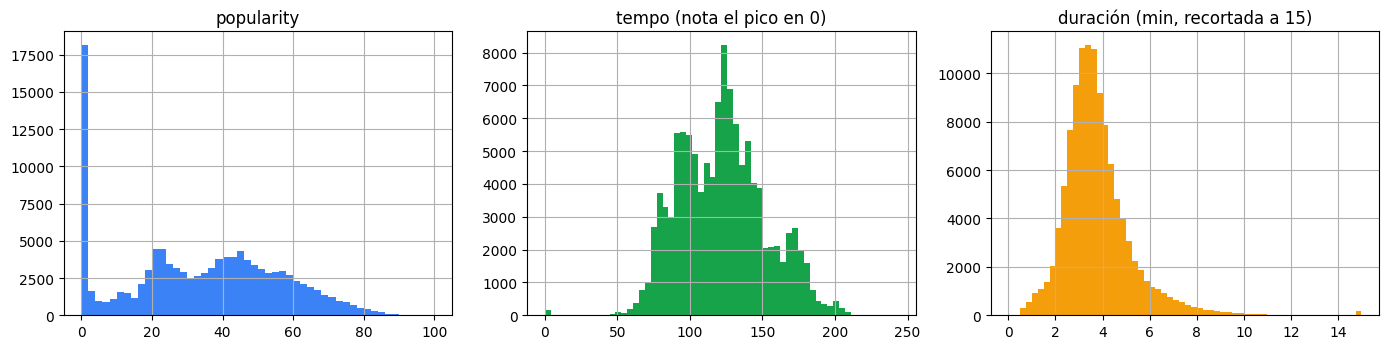

In [7]:
num = ["popularity","duration_ms","danceability","energy","valence","loudness","tempo","time_signature"]
display(spotify[num].describe().T.round(3))
chk = pd.Series({
  "popularity fuera de [0,100]": ((spotify.popularity<0)|(spotify.popularity>100)).sum(),
  "popularity = 0": (spotify.popularity==0).sum(),
  "danceability/energy/valence fuera de [0,1]": ((spotify[["danceability","energy","valence"]]<0)|(spotify[["danceability","energy","valence"]]>1)).any(axis=1).sum(),
  "tempo = 0 (imposible)": (spotify.tempo==0).sum(), "time_signature = 0 (imposible)": (spotify.time_signature==0).sum(),
  "duration_ms = 0": (spotify.duration_ms==0).sum(), "duration > 1 hora": (spotify.duration_ms>3_600_000).sum(),
  "loudness > 0 dB": (spotify.loudness>0).sum()})
display(chk.to_frame("filas"))
print("tempo mínimo > 0:", spotify.tempo[spotify.tempo>0].min(), "| máximo:", spotify.tempo.max())
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
spotify.popularity.hist(bins=50, ax=ax[0], color="#3b82f6"); ax[0].set_title("popularity")
spotify.tempo.hist(bins=60, ax=ax[1], color="#16a34a"); ax[1].set_title("tempo (nota el pico en 0)")
(spotify.duration_ms/60000).clip(upper=15).hist(bins=60, ax=ax[2], color="#f59e0b"); ax[2].set_title("duración (min, recortada a 15)")
fig.tight_layout(); fig.savefig(OUT/"spotify_numeric_distributions.png", dpi=130); plt.show()

## 6. Contenido temporal
Grammy es la única fuente con tiempo. Spotify no tiene fecha: AR-3 depende de la década del Grammy.

Grammy · rango de year: 1958 - 2019 | nulos: 0
Años sin nominaciones dentro del rango: []


,filas por año
count,62.0
mean,77.6
std,51.7
min,28.0
25%,48.0
50%,75.5
75%,88.8
max,433.0


published_at: parseables 100.0% | distintos: 4 | rango: 2017-11-28 08:03:45+00:00 -> 2020-05-19 12:10:28+00:00
updated_at: parseables 100.0% | distintos: 10 | rango: 2017-11-28 08:03:45+00:00 -> 2020-09-01 19:16:40+00:00
-> published_at/updated_at son metadatos de PUBLICACIÓN web (solo 4 valores), no fechas del premio. No sirven como dimensión temporal.


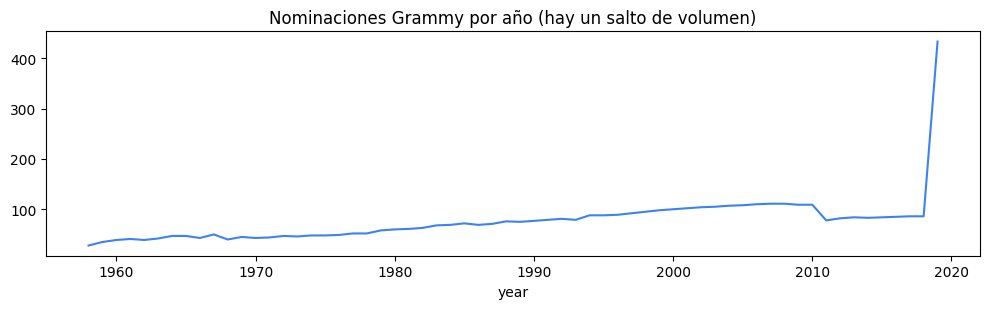

In [8]:
yrs = grammy.year
print("Grammy · rango de year:", yrs.min(), "-", yrs.max(), "| nulos:", yrs.isna().sum())
missing_years = sorted(set(range(int(yrs.min()), int(yrs.max())+1)) - set(yrs.dropna().astype(int)))
print("Años sin nominaciones dentro del rango:", missing_years)
per_year = yrs.value_counts().sort_index(); display(per_year.describe().round(1).to_frame("filas por año"))
for c in ["published_at", "updated_at"]:
    parsed = pd.to_datetime(grammy[c], errors="coerce", utc=True)
    print(f"{c}: parseables {parsed.notna().mean()*100:.1f}% | distintos: {grammy[c].nunique()} | rango: {parsed.min()} -> {parsed.max()}")
print("-> published_at/updated_at son metadatos de PUBLICACIÓN web (solo", grammy.published_at.nunique(), "valores), no fechas del premio. No sirven como dimensión temporal.")
fig, ax = plt.subplots(figsize=(10, 3.2)); per_year.plot(ax=ax, color="#3b82f6"); ax.set_title("Nominaciones Grammy por año (hay un salto de volumen)"); fig.tight_layout()
fig.savefig(OUT/"grammy_per_year.png", dpi=130); plt.show()

## 7. Consistencia entre fuentes (compatibilidad para integrar)
No existe llave común. Se evalúa el emparejamiento por nombre normalizado de artista y de canción.

In [9]:
sp_primary = spotify.artists.dropna().str.split(";").str[0].str.strip()
sp_all = set(spotify.artists.dropna().str.split(";").explode().str.strip().map(norm).dropna())
sp_primary_set = set(sp_primary.map(norm).dropna())
g_artist_raw = grammy.artist.dropna().drop_duplicates()
exact_raw = len(set(g_artist_raw.str.strip()) & set(spotify.artists.str.split(";").explode().str.strip().dropna()))
exact_norm = len(set(g_artist_raw.map(norm)) & sp_all)
rows = pd.DataFrame({"estrategia": ["Igualdad exacta (sin normalizar)", "Normalizada (acentos/mayúsculas/puntuación/'the')"],
                     "artistas Grammy distintos": len(g_artist_raw), "con coincidencia en Spotify": [exact_raw, exact_norm]})
rows["%"] = (rows["con coincidencia en Spotify"]/rows["artistas Grammy distintos"]*100).round(1); display(rows)
comp = g_artist_raw[g_artist_raw.str.contains(r" & |, |featuring| and | with ", case=False, regex=True)]
print("Créditos Grammy compuestos:", len(comp), "-> se dividen en tokens (T-07). Ejemplos:", comp.head(4).tolist())
print("Spotify primer artista vs. todos los artistas acreditados: primary =", len(sp_primary_set), "| todos =", len(sp_all))
print("\nCardinalidad: un artista Grammy puede tener varias nominaciones (1:N) y un artista Spotify varias pistas (1:N)."
      " Tras agregar nominaciones por artista, el join Spotify->artista es MANY:ONE (no multiplica filas).")
gt = set(grammy.nominee.dropna().map(title_key).dropna()); st = set(spotify.track_name.dropna().map(title_key).dropna())
print("Títulos Grammy distintos:", len(gt), "| coinciden con un título Spotify (SOLO título):", len(gt & st),
      "-> riesgo de FALSOS POSITIVOS (títulos genéricos como 'Home', 'Fire'): el match exige artista + título.")

,estrategia,artistas Grammy distintos,con coincidencia en Spotify,%
0,Igualdad exacta (sin normalizar),1658,517,31.2
1,Normalizada (acentos/mayúsculas/puntuación/'the'),1658,551,33.2


Créditos Grammy compuestos: 480 -> se dividen en tokens (T-07). Ejemplos: ['Lil Nas X Featuring Billy Ray Cyrus', 'Post Malone & Swae Lee', 'Ariana Grande & Social House', 'Shawn Mendes & Camila Cabello']
Spotify primer artista vs. todos los artistas acreditados: primary = 17627 | todos = 29762

Cardinalidad: un artista Grammy puede tener varias nominaciones (1:N) y un artista Spotify varias pistas (1:N). Tras agregar nominaciones por artista, el join Spotify->artista es MANY:ONE (no multiplica filas).


Títulos Grammy distintos: 4056 | coinciden con un título Spotify (SOLO título): 894 -> riesgo de FALSOS POSITIVOS (títulos genéricos como 'Home', 'Fire'): el match exige artista + título.


## 8. Tabla de riesgos de calidad (evidencia → riesgo → requisito)
Generada con los números de este notebook; guía las reglas de `src/rules.py` (ver `docs/quality_rules.md`).

In [10]:
pct = lambda a, b: f"{a:,} ({a/b*100:.2f}%)"
dup_pair = int(spotify.duplicated(["track_id","track_genre"]).sum())
risks = pd.DataFrame([
 ["Spotify / track_id, track_genre", f"{pct(dup_pair, len(spotify))} filas repiten el par (track_id, track_genre); {spotify.track_id.nunique():,} track_id distintos en {len(spotify):,} filas", "Doble conteo en KPIs y violación del UNIQUE del hecho", "AR-1, AR-2, AR-3", "DQ-S05, DQ-P03"],
 ["Spotify / tempo, time_signature", f"tempo=0: {int((spotify.tempo==0).sum())}; time_signature=0: {int((spotify.time_signature==0).sum())} (valores centinela imposibles)", "Promedios de tempo sesgados", "AR-1", "DQ-S06, DQ-P06"],
 ["Spotify / artists, track_name", f"{int(spotify[['artists','track_name']].isna().any(axis=1).sum())} fila sin artists/track_name", "Registro no integrable con Grammy", "AR-1..3", "DQ-S07"],
 ["Spotify / artists", f"{int(spotify.artists.str.contains(';', na=False).sum()):,} filas con varios artistas en un solo string", "Cruce por artista fallido si se compara el string completo", "AR-1..3", "DQ-P02 (primary_artist_norm)"],
 ["Spotify / popularity", f"rango [{spotify.popularity.min()}, {spotify.popularity.max()}]; {int((spotify.popularity==0).sum()):,} filas con 0", "Medida principal; fuera de rango invalidaría promedios", "AR-1, AR-3", "DQ-S03, DQ-P05"],
 ["Spotify / (índice) Unnamed: 0", "Columna índice sin significado analítico", "Contaminar el esquema del DW", "—", "DQ-P01"],
 ["Grammy / artist", f"{pct(int(grammy.artist.isna().sum()), len(grammy))} nulos, concentrados en categorías cuyo crédito está en 'workers'", "Cobertura limitada del vínculo con Spotify", "AR-1..3", "DQ-G05, DQ-P09"],
 ["Grammy / winner", f"winner=True en el 100% de las filas ({grammy.winner.nunique()} valor distinto)", "No se puede distinguir ganador de nominado: conclusión incorrecta si se asume lo contrario", "AR-1", "DQ-G07"],
 ["Grammy / nominee", f"{int(grammy.nominee.isna().sum())} nulos", "Sin vínculo por canción en esas filas", "AR-1", "DQ-G04"],
 ["Grammy / category", f"{grammy.category.nunique()} categorías; {len(variants)} con variantes de mayúsculas", "Dispersión de etiquetas si se agrupa por categoría", "AR-3", "DQ-G03, DQ-G09"],
 ["Grammy / year", f"rango {int(grammy.year.min())}–{int(grammy.year.max())}", "Año imposible corrompe la década del primer Grammy", "AR-3", "DQ-G02"],
 ["Grammy / published_at, updated_at", f"solo {grammy.published_at.nunique()} valores distintos (metadatos web)", "Usarlos como fecha del premio daría un análisis temporal falso", "AR-3", "(se descartan en transform)"],
 ["Cross-source / artist", f"coincidencia exacta {exact_raw} vs normalizada {exact_norm} de {len(g_artist_raw):,}; {len(comp)} créditos compuestos", "Falsos negativos (sin normalizar) y falsos positivos (solo título)", "AR-1..3", "DQ-P07, DQ-P08, DQ-P09, DQ-P11"],
], columns=["Dataset / Attribute", "Profiling Evidence", "Potential Quality Risk", "Related Requirement", "Rule ID(s)"])
display(risks)
risks.to_csv(OUT/"risk_table.csv", index=False)
print("Guardado:", OUT/"risk_table.csv")

,Dataset / Attribute,Profiling Evidence,Potential Quality Risk,Related Requirement,Rule ID(s)
0,"Spotify / track_id, track_genre","450 (0.39%) filas repiten el par (track_id, track_genre); 89,741 track_id di...",Doble conteo en KPIs y violación del UNIQUE del hecho,"AR-1, AR-2, AR-3","DQ-S05, DQ-P03"
1,"Spotify / tempo, time_signature",tempo=0: 157; time_signature=0: 163 (valores centinela imposibles),Promedios de tempo sesgados,AR-1,"DQ-S06, DQ-P06"
2,"Spotify / artists, track_name",1 fila sin artists/track_name,Registro no integrable con Grammy,AR-1..3,DQ-S07
3,Spotify / artists,"30,075 filas con varios artistas en un solo string",Cruce por artista fallido si se compara el string completo,AR-1..3,DQ-P02 (primary_artist_norm)
4,Spotify / popularity,"rango [0, 100]; 16,020 filas con 0",Medida principal; fuera de rango invalidaría promedios,"AR-1, AR-3","DQ-S03, DQ-P05"
5,Spotify / (índice) Unnamed: 0,Columna índice sin significado analítico,Contaminar el esquema del DW,—,DQ-P01
6,Grammy / artist,"1,840 (38.25%) nulos, concentrados en categorías cuyo crédito está en 'workers'",Cobertura limitada del vínculo con Spotify,AR-1..3,"DQ-G05, DQ-P09"
7,Grammy / winner,winner=True en el 100% de las filas (1 valor distinto),No se puede distinguir ganador de nominado: conclusión incorrecta si se asum...,AR-1,DQ-G07
8,Grammy / nominee,6 nulos,Sin vínculo por canción en esas filas,AR-1,DQ-G04
9,Grammy / category,638 categorías; 7 con variantes de mayúsculas,Dispersión de etiquetas si se agrupa por categoría,AR-3,"DQ-G03, DQ-G09"


Guardado: /home/claude/workshop-2/docs/evidence/profiling/risk_table.csv
